In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import colormaps
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
condition_map = {
    2: '5k macs',
    3: '10k macs',
    4: '1k escs, 9k macs',
    5: '5k escs, 5k macs',
    6: '9k escs, 1k macs',
    7: '10k escs',
    8: '5k escs'
}

color_gradient = colormaps['RdYlBu']

In [285]:
df = pd.read_csv('luminex_wrangled.csv')
df['analyte'] = df['analyte'].str.split('_').str[0]

# aggregate by condition
df = df.dropna(subset='concentration').groupby(['condition', 'bio_rep', 'analyte', 'saw_il1b'])[['concentration']].mean().reset_index()

# pivot such that each row represents a condition and each column represents an analyte
df = df.pivot_table(index=['condition', 'bio_rep', 'saw_il1b'], columns='analyte', values='concentration').reset_index()

# only IL-1B+
df = df[df['saw_il1b']]
df = df.drop('saw_il1b', axis=1)

# drop any columns that contain NaN
df = df.dropna(axis=1)

# drop condition 6 (far too funky)
#df = df[df['condition'] != 6]

analytes = df.columns[2:]
df

analyte,condition,bio_rep,CCL2,CCL3,CCL4,CCL5,CXCL1,CXCL10,CXCL13,CXCL5,...,IL1ra,IL4,IL6,IL8,MMP1,MMP12,MMP9,SLPI,TNFa,VCAM1
0,2,B,128.092912,196.315587,180.255075,18.683765,286.861925,0.811973,17.334325,711.464382,...,516.420478,14.250662,7.282125,996.419599,215.817830,21.326560,2284.211089,135.444983,22.089125,3991.900206
1,2,C,147.588878,328.008249,312.403835,18.750801,353.508812,0.847524,18.433529,1210.355338,...,1440.765436,14.155242,13.678140,1827.622117,223.024103,21.224241,3547.846363,135.444983,46.381542,3926.820733
2,2,D,174.469551,372.433310,346.689129,18.885011,503.552940,0.859387,18.937332,1378.375566,...,1584.490651,14.345939,26.576676,2318.681340,253.794125,21.445930,3760.342219,135.444983,51.205990,3991.900206
6,3,B,117.910817,155.337250,128.967269,18.750801,272.103547,0.966412,16.689645,628.640517,...,181.903061,13.963970,2.078521,623.507854,224.230383,21.138974,1523.444014,129.754186,14.945552,3894.196114
7,3,C,118.293849,148.330087,133.498633,18.449499,223.632978,0.853455,16.805152,698.431471,...,213.870572,14.630929,6.352635,550.671007,212.405379,21.428877,1403.651347,133.562245,17.530329,3861.513712
8,3,D,120.582121,155.438312,124.792669,18.885011,165.449009,0.841595,16.895153,638.463034,...,121.778541,14.345939,6.352635,674.760835,225.265518,21.428877,1495.966799,136.381213,13.144873,3861.513712
12,4,B,140.489962,243.628220,180.016210,18.683765,389.271990,0.735142,18.950644,1617.545958,...,585.720788,14.725651,67.834111,1901.403656,787.362440,21.207188,2450.374993,137.314082,21.032886,4056.759072
13,4,C,132.518852,230.972211,184.436077,18.885011,353.508812,0.746944,18.552486,1442.325755,...,532.323965,14.630929,36.830212,1499.465207,516.328325,21.394772,1850.269083,139.169934,19.832814,3991.900206
14,4,D,139.053786,236.507858,186.945491,18.885011,540.495951,0.711559,17.999308,1625.096410,...,526.041808,13.963970,47.824677,2507.128624,809.526549,21.292454,3008.221768,131.665457,24.523950,3795.971844
18,5,B,194.185648,182.376791,136.598596,19.288729,717.373313,0.758752,16.972411,1065.882055,...,359.784070,14.059679,187.591215,2720.757210,1165.662562,21.394772,1892.487328,131.665457,18.022867,4056.759072


### Cluster cytokines (IL-1B+)

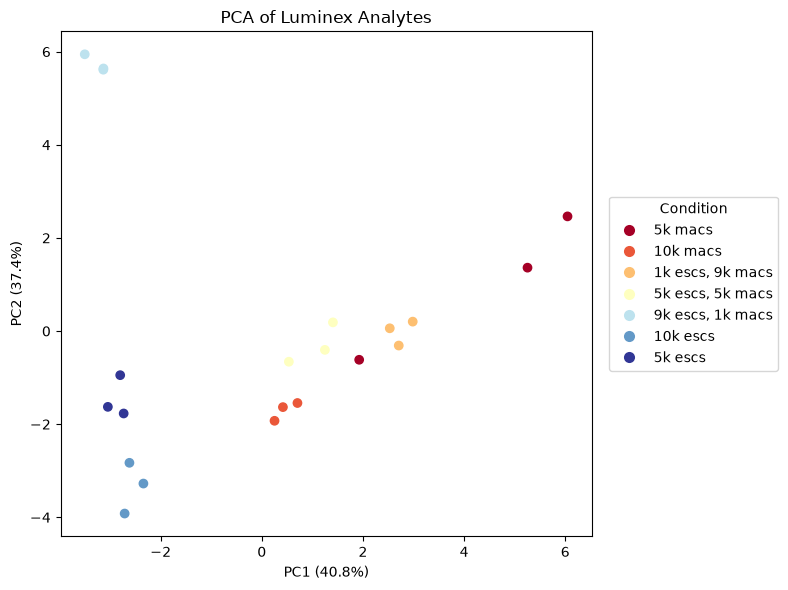

In [287]:
conditions = df['condition']
X = df.drop(columns=['condition', 'bio_rep']).values
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=4)
X_pca = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame({
    'condition': conditions,
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'PC3': X_pca[:, 2],
    'PC4': X_pca[:, 3]
})

from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(8, 6))

scatter = ax.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    c=pca_df['condition'],
    cmap='RdYlBu'
)

# build legend manually
conditions = sorted(pca_df['condition'].unique())
norm = scatter.norm
cmap = scatter.cmap

handles = [
    Line2D(
        [0], [0],
        marker='o',
        linestyle='',
        markerfacecolor=cmap(norm(condition)),
        markeredgecolor='none',
        markersize=8,
        label=condition_map[condition]
    )
    for condition in conditions
]

# Put legend outside plot on right
ax.legend(
    handles=handles,
    title='Condition',
    loc='center left',
    bbox_to_anchor=(1.02, 0.5)
)

ax.set_xlabel(
    f"PC1 "
    f"({pca.explained_variance_ratio_[0]*100:.1f}%)"
)
ax.set_ylabel(
    f"PC2 "
    f"({pca.explained_variance_ratio_[1]*100:.1f}%)"
)
ax.set_title("PCA of Luminex Analytes")

fig.tight_layout()
plt.show()

Text(0.5, 1.0, 'PC2 Loadings')

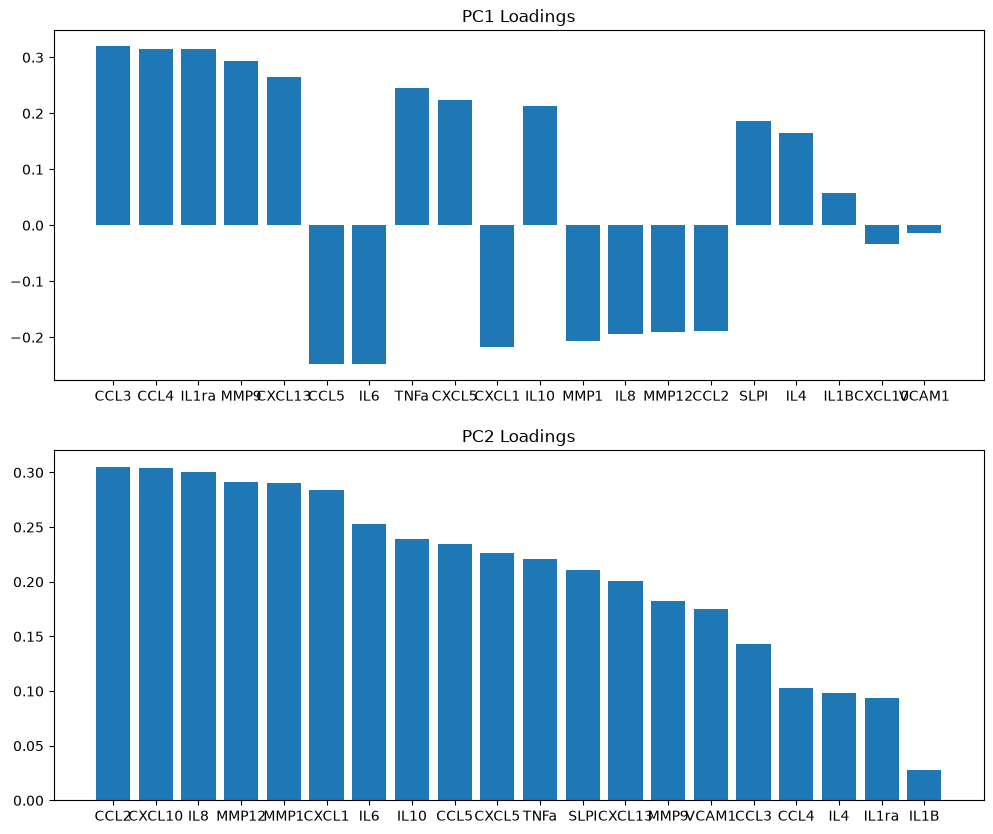

In [288]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=df.drop(columns=['condition', 'bio_rep']).columns,
    columns=['PC1', 'PC2', 'PC3', 'PC4']
)

fig, axs = plt.subplots(2, 1, figsize=(12, 10))

axs[0].bar(loadings['PC1'].sort_values(key=abs, ascending=False).index,
        loadings['PC1'].sort_values(key=abs, ascending=False).values)
axs[0].set_title('PC1 Loadings')

axs[1].bar(loadings['PC2'].sort_values(key=abs, ascending=False).index,
        loadings['PC2'].sort_values(key=abs, ascending=False).values)
axs[1].set_title('PC2 Loadings')

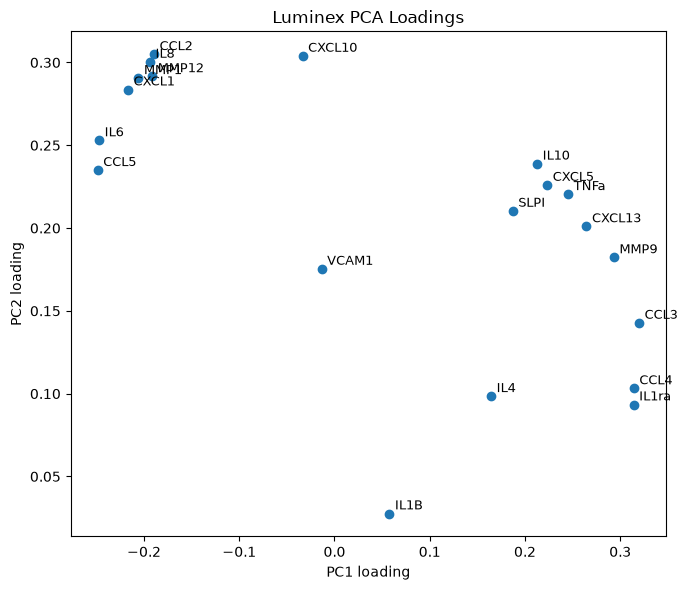

In [289]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(loadings["PC1"], loadings["PC2"])

for analyte, row in loadings.iterrows():
    ax.annotate(
        analyte,
        (row["PC1"], row["PC2"]),
        xytext=(4, 3),
        textcoords="offset points",
        fontsize=9
    )

ax.set_xlabel("PC1 loading")
ax.set_ylabel("PC2 loading")
ax.set_title("Luminex PCA Loadings")

plt.tight_layout()
plt.show()

In [290]:
def plot_cytokine(cytokine):
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.boxplot(
        data=df,
        x='condition',
        y=cytokine,
        ax=ax
    )
    ax.set_title(f"{cytokine} Concentration by Condition")
    ax.set_xlabel("Condition")
    ax.set_ylabel("Concentration")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

n_graphs = len(analytes)
current = {'i': 0}

output = widgets.Output()
btn_prev = widgets.Button(description='◀ Previous')
btn_next = widgets.Button(description='Next ▶')
label = widgets.Label()

def render():
    label.value = f"Graph {current['i']+1} / {n_graphs}"
    with output:
        clear_output(wait=True)
        cytokine = analytes[current['i']]
        plot_cytokine(cytokine)

def on_next(b):
    current['i'] = min(current['i'] + 1, n_graphs - 1)
    render()

def on_prev(b):
    current['i'] = max(current['i'] - 1, 0)
    render()

btn_next.on_click(on_next)
btn_prev.on_click(on_prev)

display(widgets.HBox([btn_prev, btn_next]), label, output)
render()

Label(value='')

Output()

In [267]:
df = df.set_index(['condition', 'bio_rep'])
df_z = (df - df.mean()) / df.std()


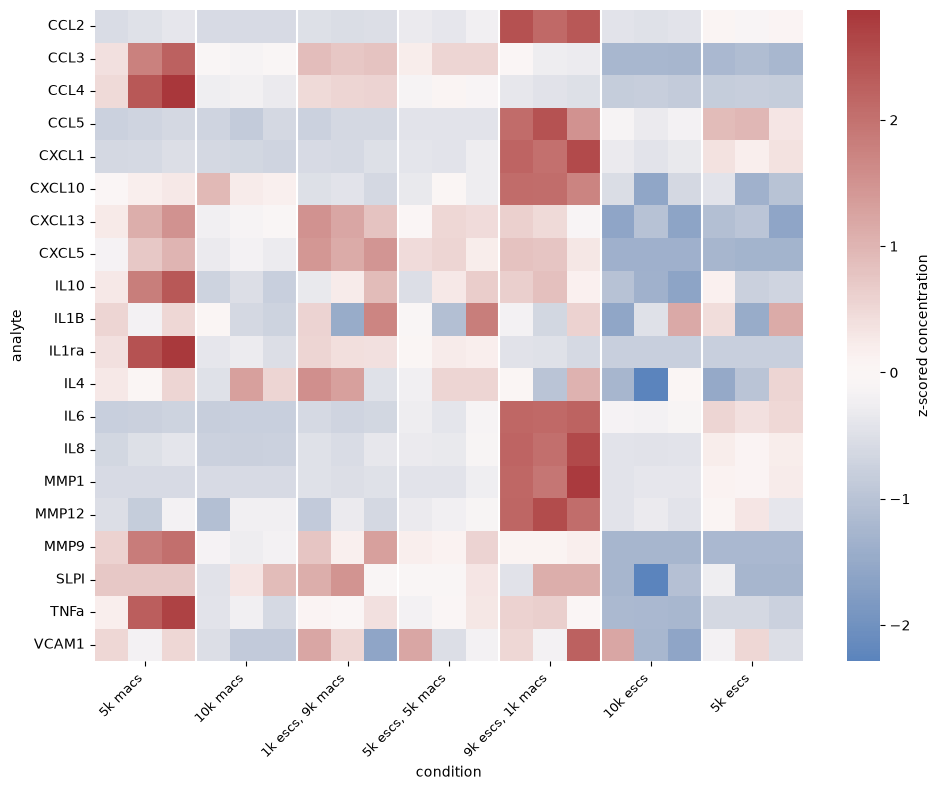

In [268]:
plot_df = df_z.T  # transpose: analytes as rows, samples as columns

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(plot_df, cmap='vlag', center=0, annot=False, cbar_kws={'label': 'z-scored concentration'}, ax=ax)

# pull condition labels directly from the MultiIndex level
conditions = df_z.index.get_level_values('condition')
unique_conditions = conditions.unique()
condition_labels = [condition_map.get(condition) for condition in unique_conditions]

# group sizes may vary — compute boundaries dynamically rather than assuming a fixed size
group_sizes = conditions.value_counts().reindex(unique_conditions)
boundaries = np.concatenate([[0], group_sizes.cumsum().values])
tick_positions = (boundaries[:-1] + boundaries[1:]) / 2

ax.set_xticks([])
ax.set_xticks(tick_positions)
ax.set_xticklabels(condition_labels, rotation=45, ha='right', fontsize=9)

for b in boundaries[1:-1]:
    ax.axvline(b, color='white', linewidth=1.5)

ax.set_xlabel('condition')
ax.set_ylabel('analyte')
plt.tight_layout()
plt.show()

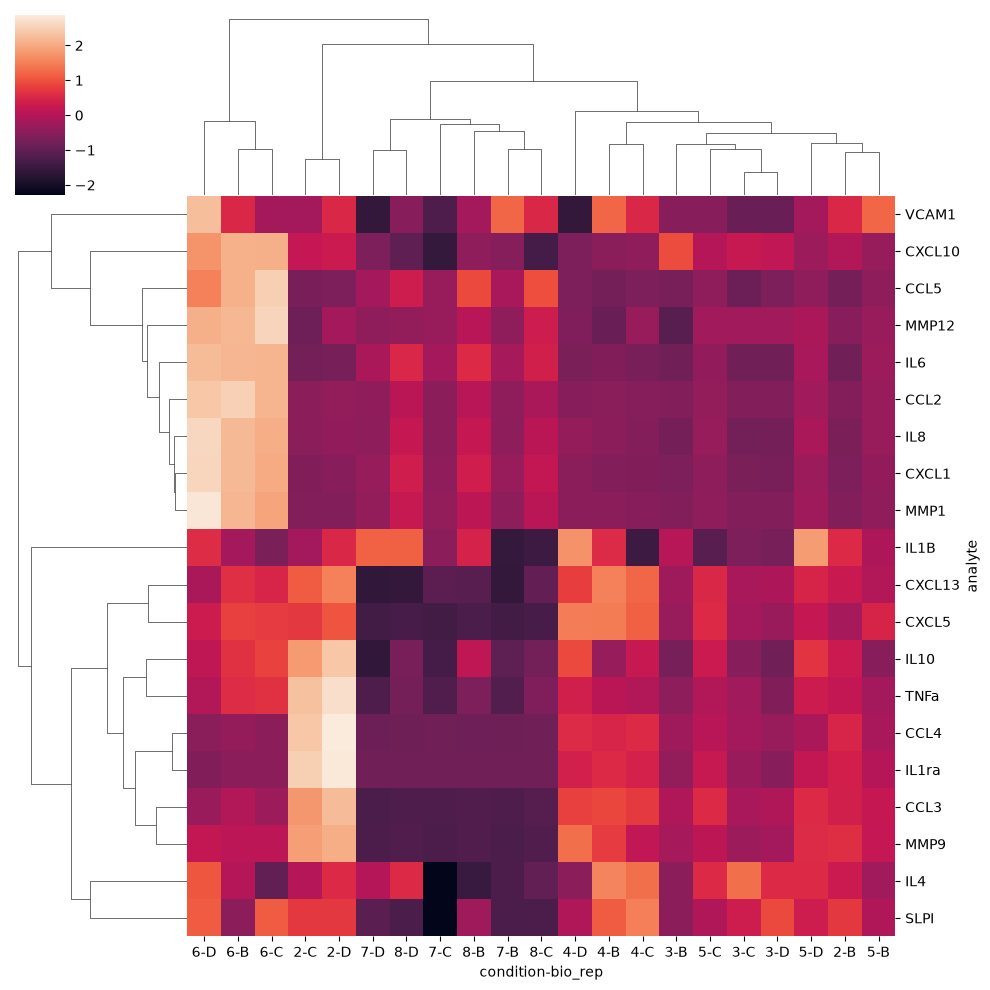

In [269]:
sns.clustermap(df_z.T)

### Adding in accurate cell counts (from DAPI/cell trace imaging)

In [291]:
cell_counts = pd.read_csv('well_summary.csv', index_col=0)

cell_counts['bio_rep'] = cell_counts['well_id'].str.extract(r'([A-Za-z]+)')
cell_counts['condition'] = cell_counts['well_id'].str.extract(r'(\d+)').astype(int)
cell_counts = cell_counts.drop(['well_id'], axis=1)

cell_counts.head()

,num cells,num ESCs,num macrophages,bio_rep,condition
0,4452,83,4369,B,2
1,1871,232,1639,B,3
2,1935,276,1659,B,4
3,1150,538,612,B,5
4,4958,4594,364,B,6


In [292]:
# MERGE

df = df.reset_index().merge(
    cell_counts,
    on=['condition', 'bio_rep']
)
#df = df.set_index(['condition', 'bio_rep'])
df

,index,condition,bio_rep,CCL2,CCL3,CCL4,CCL5,CXCL1,CXCL10,CXCL13,...,IL8,MMP1,MMP12,MMP9,SLPI,TNFa,VCAM1,num cells,num ESCs,num macrophages
0,0,2,B,128.092912,196.315587,180.255075,18.683765,286.861925,0.811973,17.334325,...,996.419599,215.817830,21.326560,2284.211089,135.444983,22.089125,3991.900206,4452,83,4369
1,1,2,C,147.588878,328.008249,312.403835,18.750801,353.508812,0.847524,18.433529,...,1827.622117,223.024103,21.224241,3547.846363,135.444983,46.381542,3926.820733,4356,112,4244
2,2,2,D,174.469551,372.433310,346.689129,18.885011,503.552940,0.859387,18.937332,...,2318.681340,253.794125,21.445930,3760.342219,135.444983,51.205990,3991.900206,3766,159,3607
3,6,3,B,117.910817,155.337250,128.967269,18.750801,272.103547,0.966412,16.689645,...,623.507854,224.230383,21.138974,1523.444014,129.754186,14.945552,3894.196114,1871,232,1639
4,7,3,C,118.293849,148.330087,133.498633,18.449499,223.632978,0.853455,16.805152,...,550.671007,212.405379,21.428877,1403.651347,133.562245,17.530329,3861.513712,1902,223,1679
5,8,3,D,120.582121,155.438312,124.792669,18.885011,165.449009,0.841595,16.895153,...,674.760835,225.265518,21.428877,1495.966799,136.381213,13.144873,3861.513712,1922,417,1505
6,12,4,B,140.489962,243.628220,180.016210,18.683765,389.271990,0.735142,18.950644,...,1901.403656,787.362440,21.207188,2450.374993,137.314082,21.032886,4056.759072,1935,276,1659
7,13,4,C,132.518852,230.972211,184.436077,18.885011,353.508812,0.746944,18.552486,...,1499.465207,516.328325,21.394772,1850.269083,139.169934,19.832814,3991.900206,1791,281,1510
8,14,4,D,139.053786,236.507858,186.945491,18.885011,540.495951,0.711559,17.999308,...,2507.128624,809.526549,21.292454,3008.221768,131.665457,24.523950,3795.971844,1897,349,1548
9,18,5,B,194.185648,182.376791,136.598596,19.288729,717.373313,0.758752,16.972411,...,2720.757210,1165.662562,21.394772,1892.487328,131.665457,18.022867,4056.759072,1150,538,612


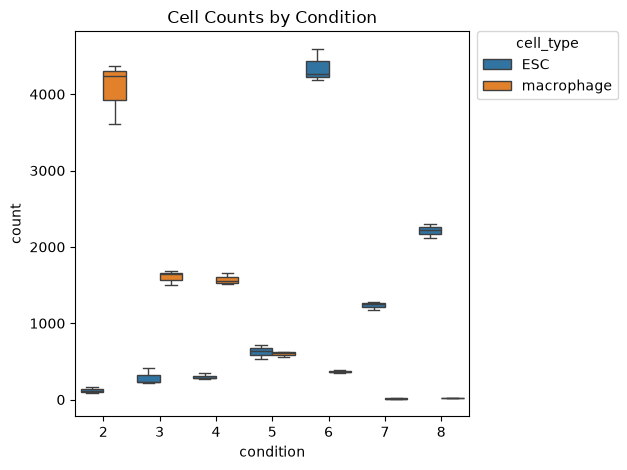

In [293]:
melted = df.melt(
    id_vars=['condition'],
    value_vars=['num ESCs', 'num macrophages'],
    var_name='cell_type',
    value_name='count'
)

ax = sns.boxplot(data=melted, x='condition', y='count', hue='cell_type')

handles, _ = plt.gca().get_legend_handles_labels()
plt.legend(handles, ['ESC', 'macrophage'], title='cell_type',
           bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
plt.title('Cell Counts by Condition')
plt.tight_layout()
plt.show()

In [ ]:
import plotly.express as px
import plotly.graph_objects as go
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

n_graphs = len(analytes)
current = {'i': 0}

output = widgets.Output()
btn_prev = widgets.Button(description='◀ Previous')
btn_next = widgets.Button(description='Next ▶')
label = widgets.Label()

def render():
    label.value = f"Graph {current['i']+1} / {n_graphs}"
    with output:
        clear_output(wait=True)
        cytokine = analytes[current['i']]

        x_col, y_col = 'num ESCs', 'num macrophages'
        sub = df[[x_col, y_col, cytokine]].dropna()

        # fit linear regression: cytokine ~ num_ESCs + num_macrophages
        X = sub[[x_col, y_col]].to_numpy()
        z = sub[cytokine].to_numpy()
        reg = LinearRegression().fit(X, z)
        r2 = r2_score(z, reg.predict(X))

        # build a grid over the observed x/y range for the fitted plane
        x_range = np.linspace(sub[x_col].min(), sub[x_col].max(), 20)
        y_range = np.linspace(sub[y_col].min(), sub[y_col].max(), 20)
        x_grid, y_grid = np.meshgrid(x_range, y_range)
        z_grid = reg.predict(
            np.column_stack([x_grid.ravel(), y_grid.ravel()])
        ).reshape(x_grid.shape)

        # scatter of the actual points
        fig = px.scatter_3d(sub, x=x_col, y=y_col, z=cytokine)
        fig.update_traces(marker=dict(size=4))

        # add the regression surface
        fig.add_trace(go.Surface(
            x=x_range, y=y_range, z=z_grid,
            opacity=0.5, showscale=False, colorscale='Reds',
            name='Linear fit'
        ))

        fig.update_layout(
            title=f"{cytokine}  (R² = {r2:.3f})",
            scene=dict(
                xaxis_title=x_col,
                yaxis_title=y_col,
                zaxis_title=cytokine
            )
        )
        fig.show()

def on_next(b):
    current['i'] = min(current['i'] + 1, n_graphs - 1)
    render()

def on_prev(b):
    current['i'] = max(current['i'] - 1, 0)
    render()

btn_next.on_click(on_next)
btn_prev.on_click(on_prev)

display(widgets.HBox([btn_prev, btn_next]), label, output)
render()

Label(value='')

Output()

### Differential expression (+/- IL-1B)

In [274]:
df = pd.read_csv('luminex_wrangled.csv')
df['analyte'] = df['analyte'].str.split('_').str[0]

# aggregate by condition
df = df.dropna(subset='concentration').groupby(['condition', 'bio_rep', 'analyte', 'saw_il1b'])[['concentration']].mean().reset_index()

# pivot such that each row represents a condition and each column represents an analyte
df = df.pivot_table(index=['condition', 'bio_rep', 'saw_il1b'], columns='analyte', values='concentration').reset_index()

df

analyte,condition,bio_rep,saw_il1b,CCL2,CCL3,CCL4,CCL5,CXCL1,CXCL10,CXCL13,...,IL4,IL6,IL8,MMP1,MMP12,MMP7,MMP9,SLPI,TNFa,VCAM1
0,2,B,True,128.092912,196.315587,180.255075,18.683765,286.861925,0.811973,17.334325,...,14.250662,7.282125,996.419599,215.817830,21.326560,NaN,2284.211089,135.444983,22.089125,3991.900206
1,2,C,True,147.588878,328.008249,312.403835,18.750801,353.508812,0.847524,18.433529,...,14.155242,13.678140,1827.622117,223.024103,21.224241,NaN,3547.846363,135.444983,46.381542,3926.820733
2,2,D,True,174.469551,372.433310,346.689129,18.885011,503.552940,0.859387,18.937332,...,14.345939,26.576676,2318.681340,253.794125,21.445930,NaN,3760.342219,135.444983,51.205990,3991.900206
3,2,E,False,116.758832,55.700796,90.715901,18.482931,240.603217,0.711559,16.370035,...,14.345939,NaN,98.614609,198.210568,21.582350,NaN,3194.437016,133.562245,3.389384,3894.196114
4,2,F,False,115.988406,52.545943,92.515446,18.549830,165.449009,0.829742,15.837237,...,15.009005,NaN,85.964039,192.030042,21.599402,NaN,2691.005635,131.665457,3.368707,3926.820733
5,2,G,False,115.988406,47.442709,88.555135,18.683765,165.449009,0.841595,15.685971,...,13.772112,NaN,60.140786,188.045105,21.565298,NaN,1741.708372,130.711660,3.039699,3861.513712
6,3,B,True,117.910817,155.337250,128.967269,18.750801,272.103547,0.966412,16.689645,...,13.963970,2.078521,623.507854,224.230383,21.138974,NaN,1523.444014,129.754186,14.945552,3894.196114
7,3,C,True,118.293849,148.330087,133.498633,18.449499,223.632978,0.853455,16.805152,...,14.630929,6.352635,550.671007,212.405379,21.428877,NaN,1403.651347,133.562245,17.530329,3861.513712
8,3,D,True,120.582121,155.438312,124.792669,18.885011,165.449009,0.841595,16.895153,...,14.345939,6.352635,674.760835,225.265518,21.428877,NaN,1495.966799,136.381213,13.144873,3861.513712
9,3,E,False,115.988406,54.928211,89.275555,18.817883,240.603217,0.835668,15.685971,...,13.675959,NaN,105.011678,199.049190,21.326560,NaN,1516.569478,139.169934,3.826538,3926.820733
